0 xor 0 = 0

0 xor 1 = 1

1 xor 0 = 1

1 xor 1 = 0

In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.quantum_info import Statevector

In [14]:
def xor(x1, x0):
    qc = QuantumCircuit(3, 1)

    if x1:  # x1 = 1
        qc.x(0)

    if x0:  # x0 = 1
        qc.x(1)

    # output register is initially |0>
    qc.cx(0, 2) # if x1 = 1, then flip output qubit
    qc.cx(1, 2) # if x0 = 1, then flip output qubit... twice 1 will flip it back to 0, if only one of them is 1, then output will be 1

    qc.measure(2, 0)

    simulator = AerSimulator()
    compiled = transpile(qc, simulator)
    result = simulator.run(compiled, shots=1024).result()
    display(qc.draw(output='mpl'))

    print(f"{x1} xor {x0} = {result.get_counts()}")

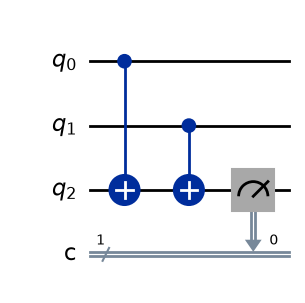

0 xor 0 = {'0': 1024}


In [15]:
xor(0, 0)

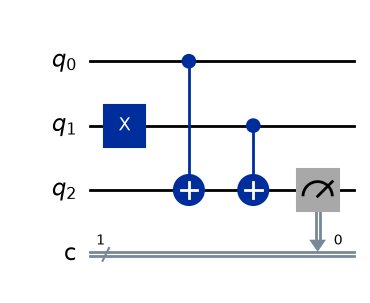

0 xor 1 = {'1': 1024}


In [16]:
xor(0, 1)

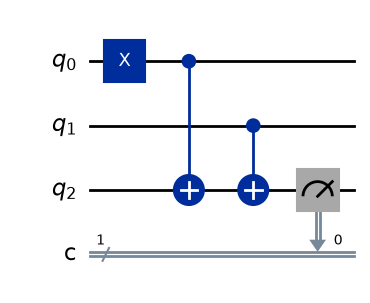

1 xor 0 = {'1': 1024}


In [17]:
xor(1, 0)

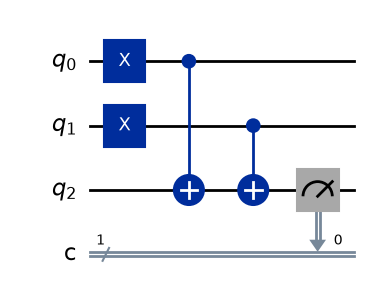

1 xor 1 = {'0': 1024}


In [18]:
xor(1, 1)

### **|0> |x1> |x0> ---> |x1 xor x0> |x1> |x0>** 

In [3]:
qc = QuantumCircuit(3, 3)

# create superposition of all 4 inputs
qc.h(0)
qc.h(1)
display(Statevector(qc).draw('latex'))

<IPython.core.display.Latex object>

In [4]:
# compute XOR into output qubit
qc.cx(0, 2)
qc.cx(1, 2)
display(Statevector(qc).draw('latex'))

<IPython.core.display.Latex object>

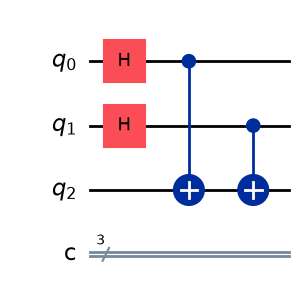

In [5]:
display(qc.draw(output='mpl'))

In [7]:
qc.measure([0, 1, 2], [0, 1, 2])
simulator = AerSimulator()
result = simulator.run(transpile(qc, simulator), shots=100).result()
print(result.get_counts())

{'000': 18, '110': 41, '101': 19, '011': 22}
